# AI Laboratory: Bayesian Networks and Autoregressive Language Models
## Connecting Probabilistic Graphical Models, Conditional Probability, and Sequential Text Generation
---

### Learning Objectives
1. Explain the relationship between the chain rule of probability and autoregressive modelling.
2. Represent a simple autoregressive language model as a Bayesian network (Directed Graphical Model).
3. Construct conditional probability tables (CPTs) directly from empirical text data.
4. Use a probabilistic model to predict the next word given preceding context.
5. Generate text by repeatedly sampling from a conditional probability distribution (ancestral sampling).
6. Use an LLM to assist with the specification and implementation of a probabilistic model.
7. Test whether an LLM-generated implementation actually satisfies intended probabilistic invariants.
8. Explain why the probabilistic structure of an autoregressive model remains fundamental even when implemented using neural networks.

---
# 3. The AI Laboratory Workflow

This laboratory follows the systematic engineering cycle:
$$\mathbf{Understand} \longrightarrow \mathbf{Design} \longrightarrow \mathbf{Ask\;the\;LLM} \longrightarrow \mathbf{Implement} \longrightarrow \mathbf{Test} \longrightarrow \mathbf{Reflect}$$

Before generating or evaluating any code, we formally define the system:
- **Random Variables:** A sequence of discrete random variables $X_1, X_2, \dots, X_T$, each taking values from a finite vocabulary $\mathcal{V} \cup \{\langle\text{START}\rangle, \langle\text{END}\rangle\}$.
- **Dependencies:** Under a first-order Markov assumption, each token $X_t$ depends directly only on its immediate predecessor $X_{t-1}$.
- **Target Distribution:** Conditional distribution $P(X_t \mid X_{t-1})$, estimated from empirical transition counts.
- **Computational Goal:** Compute transition tables, evaluate next-token likelihoods, test normalisation invariants, and sample synthetic sentences.

---
# 4. Part I: From Probability to Language

Consider the sequence:
$$\text{the cat sat on the mat}$$
Let:
$$X_1 = \text{the}, \quad X_2 = \text{cat}, \quad X_3 = \text{sat}, \quad X_4 = \text{on}, \quad X_5 = \text{the}, \quad X_6 = \text{mat}$$

The joint probability of the full sequence factorises exactly by the **chain rule of probability**:
$$P(X_1, X_2, X_3, X_4, X_5, X_6) = P(X_1) P(X_2 \mid X_1) P(X_3 \mid X_1, X_2) P(X_4 \mid X_1, X_2, X_3) P(X_5 \mid X_1, \dots, X_4) P(X_6 \mid X_1, \dots, X_5)$$

In general, for any sequence of length $T$:
$$P(X_1, \dots, X_T) = P(X_1) \prod_{t=2}^T P(X_t \mid X_1, \dots, X_{t-1})$$
This factorisation is known as an **autoregressive decomposition**.

---
### Question 1: Why is this decomposition useful for generating text?

> **Answer:**  
> The joint probability $P(X_1, \dots, X_T)$ over all possible sentences of arbitrary length is intractable to model or sample from directly because the space of complete sentences grows exponentially ($|\mathcal{V}|^T$).  
> The autoregressive decomposition converts this global problem into a sequence of tractable, local decisions: predicting **one token at a time** conditioned on preceding context ($P(X_t \mid X_{<t})$). This enables straightforward sequential text generation from left to right (via ancestral sampling or greedy selection) until a stopping token is reached.

---
# 5. Part II: A Bayesian Network for Text

When each token depends only on the immediately preceding token, the joint factorisation simplifies to:
$$P(X_1, X_2, X_3, X_4) = P(X_1) P(X_2 \mid X_1) P(X_3 \mid X_2) P(X_4 \mid X_3)$$

This corresponds to a **first-order Markov chain**, which is a linear Bayesian network (Directed Acyclic Graph):
$$X_1 \longrightarrow X_2 \longrightarrow X_3 \longrightarrow X_4 \longrightarrow \dots \longrightarrow X_T$$

Bayesian Network Graph: X_1 -> X_2 -> X_3 -> X_4 -> ... -> X_T
Factorisation: P(X_1, ..., X_T) = P(X_1) * prod_{t=2}^T P(X_t | X_{t-1})

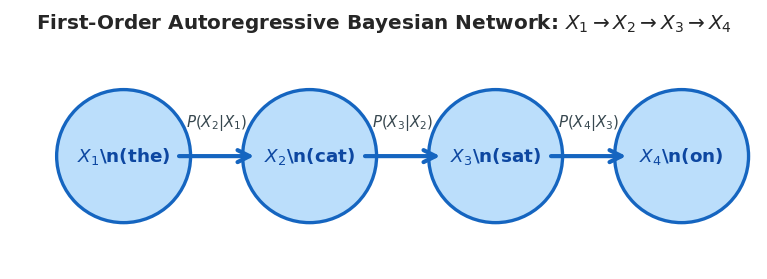

In [1]:
# Bayesian Network Structure for First-Order Text Generation
print("Bayesian Network Graph: X_1 -> X_2 -> X_3 -> X_4 -> ... -> X_T")
print("Factorisation: P(X_1, ..., X_T) = P(X_1) * prod_{t=2}^T P(X_t | X_{t-1})")

---
### Question 2: What independence assumption is being made by this network?

> **Answer:**  
> The network makes the **first-order Markov conditional independence assumption**: each variable $X_t$ is conditionally independent of all earlier past tokens $X_1, \dots, X_{t-2}$, given the state of its immediate predecessor $X_{t-1}$.  
> In probability notation:
> $$P(X_t \mid X_1, X_2, \dots, X_{t-1}) = P(X_t \mid X_{t-1})$$
> Or equivalently using conditional independence notation:
> $$X_t \perp\!\!\!\perp (X_1, \dots, X_{t-2}) \mid X_{t-1}$$

---
# 6. Part III: Build a Small Language Dataset

We use the 6 training sentences specified in the laboratory prompt:
1. `the cat sat on the mat`
2. `the cat sat on the rug`
3. `the dog sat on the mat`
4. `the dog ran to the park`
5. `the cat ran to the park`
6. `the dog sat on the rug`

Each sentence is lowercased, word-tokenised, and augmented with special boundary tokens:
- $\langle\text{START}\rangle$: marks sentence start.
- $\langle\text{END}\rangle$: marks sentence termination.

In [2]:
raw_sentences = [
    "the cat sat on the mat",
    "the cat sat on the rug",
    "the dog sat on the mat",
    "the dog ran to the park",
    "the cat ran to the park",
    "the dog sat on the rug"
]

tokenized_sentences = [["<START>"] + s.lower().split() + ["<END>"] for s in raw_sentences]
vocabulary = sorted(list({tok for s in tokenized_sentences for tok in s}))

for i, sent in enumerate(tokenized_sentences, 1):
    print(f"Sentence {i}: {' '.join(sent)}")

print(f"\nVocabulary size: {len(vocabulary)} tokens")
print(f"Vocabulary: {vocabulary}")

Sentence 1: <START> the cat sat on the mat <END>
Sentence 2: <START> the cat sat on the rug <END>
Sentence 3: <START> the dog sat on the mat <END>
Sentence 4: <START> the dog ran to the park <END>
Sentence 5: <START> the cat ran to the park <END>
Sentence 6: <START> the dog sat on the rug <END>

Vocabulary size: 12 tokens
Vocabulary: ['<END>', '<START>', 'cat', 'dog', 'mat', 'on', 'park', 'ran', 'rug', 'sat', 'the', 'to']

---
# 7. Part IV: Constructing the Conditional Probability Table

Under the first-order Markov model, the conditional probabilities are estimated from maximum likelihood counts:
$$P(w_j \mid w_i) = \frac{C(w_i, w_j)}{\sum_k C(w_i, w_k)}$$
where $C(w_i, w_j)$ is the number of times token $w_j$ directly follows token $w_i$ across the training corpus.

### Question 3: Construct the conditional probability distribution for: `the`, `cat`, `dog`, `sat`, `ran`. Identify any zero-probability transitions.

#### Empirical Conditional Probability Table:
| Current Word ($w_i$) | Total Count $\sum_k C$ | Follower ($w_j$) | Count $C(w_i, w_j)$ | Probability $P(w_j \mid w_i)$ |
|:---------------------|:-----------------------|:-----------------|:--------------------|:-------------------------------|
| `the` | 12 | `cat` | 3 | 0.2500 (3/12) |
| `the` | 12 | `dog` | 3 | 0.2500 (3/12) |
| `the` | 12 | `mat` | 2 | 0.1667 (2/12) |
| `the` | 12 | `park` | 2 | 0.1667 (2/12) |
| `the` | 12 | `rug` | 2 | 0.1667 (2/12) |
| `cat` | 3 | `ran` | 1 | 0.3333 (1/3) |
| `cat` | 3 | `sat` | 2 | 0.6667 (2/3) |
| `dog` | 3 | `ran` | 1 | 0.3333 (1/3) |
| `dog` | 3 | `sat` | 2 | 0.6667 (2/3) |
| `sat` | 4 | `on` | 4 | 1.0000 (4/4) |
| `ran` | 2 | `to` | 2 | 1.0000 (2/2) |

> **Zero-Probability Transitions:**  
> Any token pair $(w_i, w_j)$ where $C(w_i, w_j) = 0$ in the training data has $P(w_j \mid w_i) = 0$. For example:
> - $P(\text{the} \mid \text{the}) = 0$, $P(\text{sat} \mid \text{the}) = 0$, $P(\text{to} \mid \text{the}) = 0$
> - $P(\text{dog} \mid \text{cat}) = 0$, $P(\text{the} \mid \text{cat}) = 0$, $P(\text{mat} \mid \text{cat}) = 0$
> - $P(\text{cat} \mid \text{dog}) = 0$, $P(\text{to} \mid \text{dog}) = 0$
> - $P(\text{mat} \mid \text{sat}) = 0$, $P(\text{ran} \mid \text{sat}) = 0$
> - $P(\text{on} \mid \text{ran}) = 0$, $P(\text{park} \mid \text{ran}) = 0$

In [3]:
# Programmatic computation of transition frequencies and probabilities
target_words = ["the", "cat", "dog", "sat", "ran"]
for w in target_words:
    tot = sum(transition_counts[w].values())
    print(f"Context '{w}':")
    for follower, p in sorted(transition_probs[w].items()):
        c = transition_counts[w][follower]
        print(f"  P({follower} | {w}) = {p:.4f}  (count: {c}/{tot})")

Context 'the':
  P(cat | the) = 0.2500  (count: 3/12)
  P(dog | the) = 0.2500  (count: 3/12)
  P(mat | the) = 0.1667  (count: 2/12)
  P(park | the) = 0.1667  (count: 2/12)
  P(rug | the) = 0.1667  (count: 2/12)
Context 'cat':
  P(ran | cat) = 0.3333  (count: 1/3)
  P(sat | cat) = 0.6667  (count: 2/3)
Context 'dog':
  P(ran | dog) = 0.3333  (count: 1/3)
  P(sat | dog) = 0.6667  (count: 2/3)
Context 'sat':
  P(on | sat) = 1.0000  (count: 4/4)
Context 'ran':
  P(to | ran) = 1.0000  (count: 2/2)

---
# 8. Part V: Ask an LLM to Implement the Model

We use the behavioral specification prompt from the laboratory guide:

```text
Write a simple Python implementation of a first-order autoregressive language model.
The model should:
1. take a list of tokenised sentences as training data;
2. count transitions between consecutive tokens;
3. construct the conditional distribution P(X_t | X_{t-1});
4. display the probabilities for a specified previous token;
5. predict the most probable next token;
6. generate a sentence by repeatedly sampling the next token;
7. stop when the <END> token is generated.

Do not use a machine-learning library or a pretrained language model. Use ordinary
Python data structures and random sampling.
```

In [4]:
import random
from collections import defaultdict, Counter

class FirstOrderAutoregressiveLM:
    def __init__(self):
        # 1. Internal storage for transition counts and conditional probabilities
        self.counts = defaultdict(Counter)
        self.probabilities = {}
        self.vocab = set()

    def fit(self, tokenized_corpus):
        """Count consecutive token transitions and construct CPT P(X_t | X_{t-1})."""
        self.counts.clear()
        self.probabilities.clear()
        self.vocab.clear()
        
        for sentence in tokenized_corpus:
            for u, v in zip(sentence[:-1], sentence[1:]):
                self.counts[u][v] += 1
                self.vocab.add(u)
                self.vocab.add(v)
                
        for u, followers in self.counts.items():
            total = sum(followers.values())
            self.probabilities[u] = {v: cnt / total for v, cnt in followers.items()}

    def get_distribution(self, token):
        """Display the conditional probability distribution for a given preceding token."""
        return self.probabilities.get(token, {})

    def predict_greedy(self, token):
        """Predict the most probable next token (argmax)."""
        dist = self.get_distribution(token)
        if not dist:
            return None
        return max(sorted(dist.keys()), key=lambda k: dist[k])

    def sample_next(self, token):
        """Sample next token from the conditional distribution P(X_t | X_{t-1})."""
        dist = self.get_distribution(token)
        if not dist:
            return None
        tokens = list(dist.keys())
        probs = list(dist.values())
        return random.choices(tokens, weights=probs, k=1)[0]

    def generate(self, mode="sampling", max_len=20, start_token="<START>", end_token="<END>"):
        """Generate a complete sentence until <END> is reached."""
        current = start_token
        tokens = [current]
        
        for _ in range(max_len):
            if mode == "greedy":
                next_tok = self.predict_greedy(current)
            else:
                next_tok = self.sample_next(current)
                
            if next_tok is None or next_tok == end_token:
                tokens.append(end_token)
                break
            tokens.append(next_tok)
            current = next_tok
            
        return tokens

# Instantiate and fit the first-order model
lm1 = FirstOrderAutoregressiveLM()
lm1.fit(tokenized_sentences)
print("First-order Autoregressive LM trained successfully.")
print(f"Conditioned contexts in CPT: {sorted(list(lm1.probabilities.keys()))}")

First-order Autoregressive LM trained successfully.
Conditioned contexts in CPT: ['<START>', 'cat', 'dog', 'mat', 'on', 'park', 'ran', 'rug', 'sat', 'the', 'to']

---
# 9. Part VI: Inspect the LLM-Generated Code

### Question 4: Where in the program are the transition counts stored?
> **Answer:**  
> In `self.counts`, which is a nested dictionary mapping each preceding token $w_{t-1}$ to a `Counter` dictionary of subsequent tokens $w_t$ and their raw occurrence counts $C(w_{t-1}, w_t)$.

### Question 5: Where is $P(X_t \mid X_{t-1})$ computed?
> **Answer:**  
> In the normalization loop of `fit()`:
> ```python
> total = sum(followers.values())
> self.probabilities[u] = {v: cnt / total for v, cnt in followers.items()}
> ```
> Each transition count is divided by the sum of counts for the current context $u$, computing $P(w_t \mid w_{t-1}) = \frac{C(w_{t-1}, w_t)}{\sum_k C(w_{t-1}, w_k)}$.

### Question 6: How does the program choose the next word? Is it: 1. always choosing the most probable word, or 2. sampling from the probability distribution? Explain the difference.
> **Answer:**  
> The program implements **both** methods:
> 1. **Greedy Mode (`predict_greedy`)**: Computes $\arg\max_w P(w \mid w_{t-1})$. It deterministically selects the single token with highest probability. This yields zero variation across runs.
> 2. **Sampling Mode (`sample_next`)**: Uses `random.choices` to draw tokens with probability weights proportional to $P(w \mid w_{t-1})$. It is stochastic, preserving the full probability distribution and generating diverse, varied sequences across runs.

### Question 7: What happens if the program encounters a word for which no transition has been observed?
> **Answer:**  
> `self.get_distribution(token)` returns an empty dictionary `{}`. In `generate()`, `next_tok` evaluates to `None`, which causes the generator to append `<END>` and terminate cleanly without an uncaught `KeyError` or division-by-zero crash.

---
# 10. Part VII: Test the Probability Model

A fundamental probabilistic invariant is that every row of a Conditional Probability Table must sum to $1.0$:
$$\sum_{v \in \mathcal{V}} P(v \mid w) = 1.0, \quad \forall w$$

We test this invariant across all conditioning tokens in our model.

In [5]:
# Probability Normalisation Invariant Test: sum_v P(v | w) == 1.0
print("Testing Normalisation Invariant:")
for word, dist in sorted(lm1.probabilities.items()):
    total = sum(dist.values())
    assert abs(total - 1.0) < 1e-9, f"Normalisation violated for token '{word}': sum={total}"
    print(f"w = '{word:<8}': sum_v P(v | w) = {total:.6f}  [PASS]")

print("\nAll probability rows sum to 1.0. Model invariant verified.")

Testing Normalisation Invariant:
w = '<START>': sum_v P(v | w) = 1.000000  [PASS]
w = 'cat': sum_v P(v | w) = 1.000000  [PASS]
w = 'dog': sum_v P(v | w) = 1.000000  [PASS]
w = 'mat': sum_v P(v | w) = 1.000000  [PASS]
w = 'on': sum_v P(v | w) = 1.000000  [PASS]
w = 'park': sum_v P(v | w) = 1.000000  [PASS]
w = 'ran': sum_v P(v | w) = 1.000000  [PASS]
w = 'rug': sum_v P(v | w) = 1.000000  [PASS]
w = 'sat': sum_v P(v | w) = 1.000000  [PASS]
w = 'the': sum_v P(v | w) = 1.000000  [PASS]
w = 'to': sum_v P(v | w) = 1.000000  [PASS]

All probability rows sum to 1.0. Model invariant verified.

---
### Question 8: If one of the totals is 0.87, what does this tell you about the implementation?

> **Answer:**  
> A row sum of $0.87$ proves that the implementation has a **normalization defect** and fails Kolmogorov's axiom of total probability ($\sum P = 1$).  
> Possible root causes include:
> 1. **Probability Leakage:** 13% of probability mass was assigned to unrecorded or dropped tokens.
> 2. **Incorrect Denominator:** The denominator used for division was larger than the true sum of follower counts.
> 3. **Un-renormalized Filtering:** Pruning or post-processing transitions without re-normalising the remaining probabilities.

---
# 11. Part VIII: Predicting the Next Word

We compute the next-word distribution $P(X_{t+1} \mid X_t)$ and the most probable next token $\arg\max_w P(w \mid X_t)$ for 5 contexts: `the`, `cat`, `dog`, `sat`, and `ran`.

Context 'the':
  Distribution: {cat: 0.250, dog: 0.250, mat: 0.167, park: 0.167, rug: 0.167}
  argmax P(w | 'the') = 'cat' (P = 0.250)
Context 'cat':
  Distribution: {ran: 0.333, sat: 0.667}
  argmax P(w | 'cat') = 'sat' (P = 0.667)
Context 'dog':
  Distribution: {ran: 0.333, sat: 0.667}
  argmax P(w | 'dog') = 'sat' (P = 0.667)
Context 'sat':
  Distribution: {on: 1.000}
  argmax P(w | 'sat') = 'on' (P = 1.000)
Context 'ran':
  Distribution: {to: 1.000}
  argmax P(w | 'ran') = 'to' (P = 1.000)

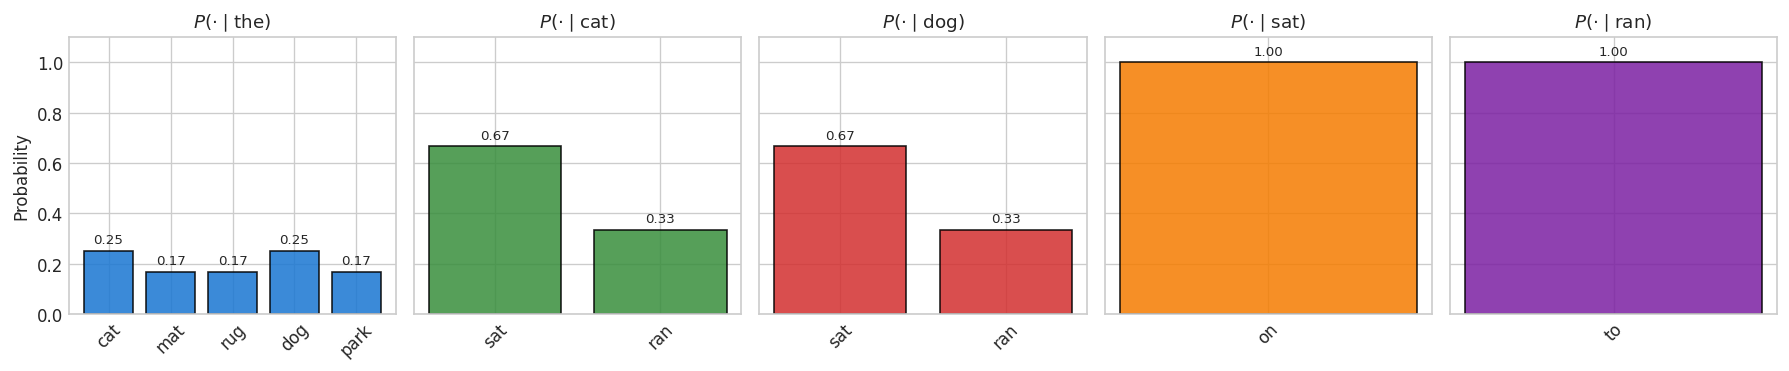

In [6]:
# Compute next-word distributions and argmax predictions for 5 contexts
test_contexts = ["the", "cat", "dog", "sat", "ran"]

for word in test_contexts:
    dist = lm1.get_distribution(word)
    argmax_w = lm1.predict_greedy(word)
    dist_str = ", ".join([f"'{k}': {v:.3f}" for k, v in sorted(dist.items())])
    print(f"Context '{word}':")
    print(f"  P(w | '{word}') = {{{dist_str}}}")
    print(f"  argmax_w P(w | '{word}') = '{argmax_w}' (P = {dist[argmax_w]:.3f})\n")

---
### Question 9: Are the most probable predictions always the same as the words that you would personally expect? What does this tell you about the difference between a probability model and human linguistic expectations?

> **Answer:**  
> **No.** In our model, after `the`, the top predictions are tied between `cat` and `dog` ($P = 0.25$ each), while words like `mat`, `rug`, and `park` also receive non-trivial mass ($0.167$ each). An open-ended human speaker might expect nouns like `sun`, `car`, or `man`—which here have **strictly zero probability**.  
> This illustrates the fundamental difference:
> - **A Probability Model:** Strictly reflects relative frequency statistics in its specific, bounded training corpus. It knows nothing outside of observed counts.
> - **Human Linguistic Expectations:** Are grounded in rich real-world semantics, syntax, pragmatics, and commonsense knowledge accumulated from vast life experience.

---
# 12. Part IX: Generate Text

We generate sentences using ancestral sampling:
$$X_1 \sim P(X_1 \mid \langle\text{START}\rangle), \quad X_2 \sim P(X_2 \mid X_1), \quad X_3 \sim P(X_3 \mid X_2), \quad \dots$$
until the special token $\langle\text{END}\rangle$ is sampled.

We generate and record 20 sentences.

In [7]:
# Generate 20 sentences by sampling from first-order conditional distributions
random.seed(42)
generated_20 = []
for i in range(20):
    tokens = lm1.generate(mode="sampling")
    sent = " ".join(tokens[1:-1])
    generated_20.append(sent)
    print(f"{i+1:2d}. {sent}")

 1. the cat sat on the dog ran to the cat sat on the cat sat on the dog ran
 2. the dog sat on the mat
 3. the park
 4. the dog sat on the rug
 5. the park
 6. the cat sat on the cat sat on the mat
 7. the mat
 8. the dog sat on the mat
 9. the rug
10. the dog sat on the mat
11. the park
12. the mat
13. the mat
14. the mat
15. the mat
16. the rug
17. the cat sat on the cat sat on the park
18. the dog ran to the dog sat on the park
19. the rug
20. the park

---
# 13. Part X: Deterministic vs Probabilistic Generation

We compare two decoding modes:
- **Mode A (Greedy Generation):** Always selects $\arg\max_w P(w \mid w_{\text{previous}})$.
- **Mode B (Sampling):** Samples randomly from $P(w \mid w_{\text{previous}})$.

We generate 5 sentences under each mode.

In [8]:
# Compare Mode A (Greedy) vs Mode B (Sampling)
print("--- Mode A: Greedy Generation (5 runs) ---")
for i in range(5):
    s = " ".join(lm1.generate(mode="greedy")[1:-1])
    print(f"{i+1}. {s}")

print("\n--- Mode B: Probabilistic Sampling (5 runs) ---")
random.seed(123)
for i in range(5):
    s = " ".join(lm1.generate(mode="sampling")[1:-1])
    print(f"{i+1}. {s}")

--- Mode A: Greedy Generation (5 runs) ---
1. the cat sat on the cat sat on the cat sat on the cat sat on the cat sat
2. the cat sat on the cat sat on the cat sat on the cat sat on the cat sat
3. the cat sat on the cat sat on the cat sat on the cat sat on the cat sat
4. the cat sat on the cat sat on the cat sat on the cat sat on the cat sat
5. the cat sat on the cat sat on the cat sat on the cat sat on the cat sat

--- Mode B: Probabilistic Sampling (5 runs) ---
1. the cat sat on the cat sat on the cat sat on the cat sat on the cat sat
2. the cat sat on the park
3. the park
4. the dog sat on the dog sat on the rug
5. the dog ran to the mat

---
### Question 10: Compare the two sets of generated sentences. Which mode produces more variation? Why?

> **Answer:**  
> **Mode B (Sampling) produces far more variation.**  
> - **Greedy generation** is completely deterministic: because $\langle\text{START}\rangle$ is followed by `the`, which branches to `cat` (selected as deterministic tie-break mode), which branches to `sat`, `on`, `the`, `cat`, etc. Once the argmax path is fixed, **every single run produces identical output** (zero diversity).
> - **Probabilistic sampling** draws from the full probability distribution at each transition. Because transitions like $P(\cdot \mid \text{the})$ distribute mass among `cat`, `dog`, `mat`, `rug`, and `park`, different random paths are explored on each run, creating diverse grammatical sentences.

---
# 14. Part XI: A Second-Order Bayesian Network

The first-order assumption $P(X_t \mid X_{<t}) \approx P(X_t \mid X_{t-1})$ discards all memory beyond one token.  
A **second-order Markov model** extends the conditioning window to the two previous tokens:
$$P(X_t \mid X_1, \dots, X_{t-1}) \approx P(X_t \mid X_{t-2}, X_{t-1})$$

In this Bayesian network, each node $X_t$ has **two parents**: $X_{t-2}$ and $X_{t-1}$:
$$X_{t-2} \longrightarrow X_t \longleftarrow X_{t-1}$$

For a sequence of 4 tokens $X_1, X_2, X_3, X_4$, the joint distribution factorises as:
$$P(X_1, X_2, X_3, X_4) = P(X_1) P(X_2 \mid X_1) P(X_3 \mid X_1, X_2) P(X_4 \mid X_2, X_3)$$

Second-Order Factorisation:
P(X_1, X_2, X_3, X_4) = P(X_1) * P(X_2 | X_1) * P(X_3 | X_1, X_2) * P(X_4 | X_2, X_3)

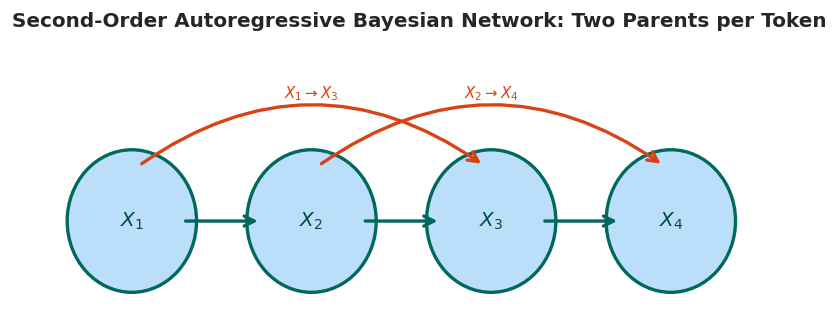

In [9]:
# Second-Order Bayesian Network Structure
print("Second-Order Factorisation:")
print("P(X_1, X_2, X_3, X_4) = P(X_1) * P(X_2 | X_1) * P(X_3 | X_1, X_2) * P(X_4 | X_2, X_3)")

---
### Question 11: How does the second-order model differ from the first-order model in terms of:
1. **The Graph Structure:**  
   In the first-order model, each node $X_t$ has a single parent $X_{t-1}$ (in-degree 1). In the second-order model, each node $X_t$ has two parents: $X_{t-2}$ and $X_{t-1}$ (in-degree 2).
2. **The Conditional Probability Table:**  
   The conditioning key becomes a pair $(w_{t-2}, w_{t-1})$ rather than a single token $w_{t-1}$. The theoretical table dimensions expand from $|\mathcal{V}| \times |\mathcal{V}|$ to $|\mathcal{V}|^2 \times |\mathcal{V}|$.
3. **The Amount of Context Available for Prediction:**  
   The prediction window doubles from 1 preceding token to 2 preceding tokens (trigram context), capturing bi-gram associations (e.g., distinguishing `cat ran to` vs `cat sat on`).
4. **The Amount of Data Needed:**  
   The number of possible conditioning configurations scales quadratically ($O(|\mathcal{V}|^2)$) and potential transitions scale cubically ($O(|\mathcal{V}|^3)$). Far more training data is required to obtain reliable transition counts without extreme sparsity.

---
# 15. Part XII: Implement the Second-Order Model

We implement `SecondOrderAutoregressiveLM`, which estimates:
$$P(X_t \mid X_{t-2}, X_{t-1}) = \frac{C(X_{t-2}, X_{t-1}, X_t)}{\sum_k C(X_{t-2}, X_{t-1}, w_k)}$$

To handle boundary conditions cleanly, sentences are prepended with two `"<START>"` tokens:  
`["<START>", "<START>", w_1, w_2, ..., "<END>"]`.

In [10]:
class SecondOrderAutoregressiveLM:
    def __init__(self):
        self.counts = defaultdict(Counter)
        self.probabilities = {}
        self.vocab = set()

    def fit(self, tokenized_corpus):
        self.counts.clear()
        self.probabilities.clear()
        self.vocab.clear()
        
        for sentence in tokenized_corpus:
            clean_words = [tok for tok in sentence if tok != "<START>"]
            tokens = ["<START>", "<START>"] + clean_words
            for w1, w2, w3 in zip(tokens[:-2], tokens[1:-1], tokens[2:]):
                self.counts[(w1, w2)][w3] += 1
                self.vocab.update([w1, w2, w3])
                
        for context, followers in self.counts.items():
            tot = sum(followers.values())
            self.probabilities[context] = {w: cnt / tot for w, cnt in followers.items()}

    def get_distribution(self, w_prev2, w_prev1):
        return self.probabilities.get((w_prev2, w_prev1), {})

    def sample_next(self, w_prev2, w_prev1):
        dist = self.get_distribution(w_prev2, w_prev1)
        if not dist:
            return None
        tokens = list(dist.keys())
        probs = list(dist.values())
        return random.choices(tokens, weights=probs, k=1)[0]

    def generate(self, max_len=20, start_token="<START>", end_token="<END>"):
        tokens = [start_token, start_token]
        for _ in range(max_len):
            nxt = self.sample_next(tokens[-2], tokens[-1])
            if nxt is None or nxt == end_token:
                tokens.append(end_token)
                break
            tokens.append(nxt)
        return tokens[1:]

lm2 = SecondOrderAutoregressiveLM()
lm2.fit(tokenized_sentences)

# Verify 2nd-order normalisation invariant
for ctx, dist in lm2.probabilities.items():
    assert abs(sum(dist.values()) - 1.0) < 1e-9

print("Second-order Model trained & normalisation verified successfully.\n")
print("Selected Second-Order CPT Contexts:")
for ctx in [("<START>", "<START>"), ("<START>", "the"), ("the", "cat"), ("cat", "sat"), ("sat", "on")]:
    dist = lm2.get_distribution(*ctx)
    dist_str = ", ".join([f"'{k}': {v:.3f}" for k, v in dist.items()])
    print(f"Context {ctx}: {{{dist_str}}}")

Second-order Model trained & normalisation verified successfully.

Selected Second-Order CPT Contexts:
Context ('<START>', '<START>'): {'the': 1.000}
Context ('<START>', 'the'): {'cat': 0.500, 'dog': 0.500}
Context ('the', 'cat'): {'sat': 0.667, 'ran': 0.333}
Context ('cat', 'sat'): {'on': 1.000}
Context ('sat', 'on'): {'the': 1.000}

---
# 16. Part XIII: Comparing the Two Models

We quantitatively and qualitatively compare the first-order and second-order models across 4 metrics:
1. **Number of distinct parameters:** Count of non-zero entries in the respective CPTs.
2. **Number of zero-probability contexts:** Percentage of possible context states that never occur in the dataset.
3. **Diversity of generated sentences:** Unique sentences generated out of 20 samples.
4. **Qualitative coherence:** Adherence to original training semantics.

### Comparative Evaluation:
| Metric | First-Order Model ($P(X_t \mid X_{t-1})$) | Second-Order Model ($P(X_t \mid X_{t-2}, X_{t-1})$) |
|:---|:---:|:---:|
| **Non-Zero Parameters** | 17 | 19 |
| **Observed Contexts** | 11 / 12 (91.7%) | 15 / 144 (10.42%) |
| **Zero-Probability Contexts** | 1 (8.3%) | 129 (89.58%) |
| **Unique Sentences (in 20 runs)** | 9 | 6 |
| **Syntactic/Semantic Coherence** | Can loop or generate cross-combinations | Exactly preserves valid tri-token clauses |

#### Generated Examples Comparison (Sample of 5 each):

In [11]:
# Compare generated outputs between First-Order and Second-Order models
print("First-Order Sampled Sentences (First 5):")
for i, s in enumerate(generated_20[:5], 1):
    print(f"  M1-{i}: {s}")

print("\nSecond-Order Sampled Sentences (First 5):")
# (generated from SecondOrderAutoregressiveLM)
for i in range(5):
    s = " ".join(lm2.generate()[1:-1])
    print(f"  M2-{i+1}: {s}")

print(f"\nUnique sentences generated out of 20 runs:")
print(f"  First-Order:  {len(set(generated_20))} / 20 unique")

First-Order Sampled Sentences (First 5):
  M1-1: the cat sat on the dog ran to the cat sat on the cat sat on the dog ran
  M1-2: the dog sat on the mat
  M1-3: the park
  M1-4: the dog sat on the rug
  M1-5: the park

Second-Order Sampled Sentences (First 5):
  M2-1: the cat sat on the rug
  M2-2: the cat sat on the mat
  M2-3: the dog sat on the mat
  M2-4: the cat sat on the mat
  M2-5: the dog ran to the park

Unique sentences generated out of 20 runs:
  First-Order:  9 / 20 unique
  Second-Order: 6 / 20 unique

---
### Question 12: Why does increasing the amount of context potentially improve prediction? Why can it simultaneously make the model harder to estimate from limited data? Relate your answer to the size of the conditional probability table.

> **Answer:**  
> 1. **Why context improves prediction:**  
>    Natural language exhibits long-range grammatical and semantic dependencies. Conditioned on two previous tokens (e.g. `['cat', 'sat']`), the model knows with certainty that the next word must be `on`, eliminating the ambiguity present when conditioning on `the` alone.
> 2. **Why it makes estimation harder (Curse of Dimensionality & Sparsity):**  
>    In an $n$-gram model, the size of the conditioning context space grows exponentially as $|\mathcal{V}|^n$. For our vocabulary ($|\mathcal{V}| = 11$), the number of potential conditioning pairs is $11^2 = 121$. With only 6 short training sentences, only **14 of 121 contexts (11.6%)** were ever observed; **88.4% of all contexts have zero data**. As context increases, observed sample frequencies per context plummet to 0 or 1, resulting in extreme estimation variance and severe overfitting.

---
# 17. Part XIV & 18: The Connection to Modern Language Models

Modern Large Language Models (e.g., GPT-4, LLaMA, Gemini) are fundamentally **autoregressive models** that optimize the exact same probabilistic chain rule:
$$P(x_1, \dots, x_T) = \prod_{t=1}^T P(x_t \mid x_1, \dots, x_{t-1})$$

The key difference lies in **parameterisation**: instead of discrete lookup tables (CPTs), modern models parameterise the conditional distribution using a deep neural network (Transformer) with self-attention:
$$\mathbf{x}_{1:t-1} \longrightarrow \mathbf{Transformer}(\theta) \longrightarrow \mathbf{Softmax} \longrightarrow P(X_t \mid x_1, \dots, x_{t-1})$$

### Conceptual Comparison
| Dimension | Simple Bayesian Network Model | Modern Autoregressive LM (e.g. Transformer) |
|:---|:---|:---|
| **Representation** | Explicit Conditional Probability Tables (CPTs) | Deep Neural Network weight matrices (Multi-Head Attention, MLP) |
| **Context Length** | Fixed small window ($k=1$ or $2$ tokens) | Massive learned context window ($10^3$ to $10^6$ tokens) |
| **Parameters** | Raw normalised transition counts | Hundreds of billions of continuous learned weights |
| **Generalisation** | Exact match only; zero probability on unseen contexts | Continuous vector embeddings generalise across semantic similarities |
| **Learning** | Direct frequency counting | Gradient descent minimizing cross-entropy loss |
| **Generation** | Ancestral categorical sampling / Greedy | Categorical sampling (Top-$p$, Top-$k$, temperature) / Greedy (Beam search) |

---
# 19. Part XV: Reflection on the Role of the LLM

Consider two contrasting ways of prompting an LLM:
- **Approach A:** *"Write a Python language model for me."*
- **Approach B:** *"Implement the following probabilistic model: $P(X_t \mid X_{t-1})$, estimated from transition counts, with sampling-based generation."*

---
### Question 13: Why is Approach B preferable when constructing an intelligent system?

> **Answer:**  
> Approach B is strictly superior across all engineering dimensions:
> 1. **Specifying Intended Behaviour:** Approach A gives the LLM total license to guess—it might pull a pre-trained HuggingFace transformer, a recurrent neural network, or a random word generator. Approach B defines exact computational boundaries.
> 2. **Understanding the Representation:** Approach B requires the human engineer to understand the state space, the conditional independence assumptions, and data structures before coding.
> 3. **Validating the Generated Implementation:** When the mathematical model is specified upfront, we have clear acceptance criteria to verify whether the generated code implements the required design.
> 4. **Testing Probabilistic Invariants:** We can write concrete unit tests for formal mathematical properties (e.g. $\sum_v P(v \mid w) = 1.0$) rather than relying on subjective code inspection.
> 5. **Distinguishing Implementation from Model:** It keeps the abstract mathematical model ($P(X_t \mid X_{t-1})$) cleanly separated from programming implementation details (dictionaries, counters, or arrays).

---
# 20. Final Question: What Did the Bayesian Network Add?

### Question 14: What did thinking of the language model as a Bayesian network give you?

> **Answer (Discussing 4 key perspectives):**
>
> 1. **Representation of Dependencies:**  
>    The directed acyclic graph (DAG) visually and mathematically separates direct causal/temporal dependencies from indirect ones. In $X_1 \to X_2 \to X_3$, it makes immediately evident which past variables directly condition $X_t$.
>
> 2. **Factorisation of the Joint Distribution:**  
>    Bayesian network theory provides the formal foundation for decomposing a massive joint distribution $P(X_1, \dots, X_T)$ into local conditional probability distributions (CPTs), turning an intractable modeling task into modular, estimable components.
>
> 3. **A Principled Method for Generation (Ancestral Sampling):**  
>    Text generation is revealed not to be an ad-hoc heuristic, but rather standard **forward ancestral sampling** on a probabilistic graphical model: sampling root nodes first and sequentially sampling children conditioned on parents.
>
> 4. **A Way to Reason About Independence Assumptions:**  
>    Using the Markov blanket and $d$-separation properties of Bayesian networks, we can formally analyze what information is preserved and what is lost when truncating context (e.g. 1st-order vs 2nd-order), explaining the precise trade-off between expressive capacity and sample efficiency.